# MSCS 634: Data Mining and Machine Learning
## Lab 3: K-Means and K-Medoids Clustering

**Name:** Nikita Metha  
**Course:** MSCS 634: Data Mining and Machine Learning  
**Assignment:** Clustering Analysis with the Wine Dataset

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.datasets import load_wine
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42  # Keep results reproducible and consistent with Lab 2.
N_CLUSTERS = 3  # Match the Wine dataset's three known classes.
pd.set_option('display.max_columns', None)

## Step 1: Load and Prepare the Dataset

In [3]:
wine = load_wine()
X = pd.DataFrame(wine.data, columns=wine.feature_names)
y = pd.Series(wine.target, name='class')

# Check for missing values; no imputation is needed if none are present.
missing_count = X.isna().sum().sum()
print(f'Missing values: {missing_count}')

# Remove exact duplicate feature rows and keep the corresponding labels aligned.
duplicate_mask = X.duplicated()
duplicate_count = duplicate_mask.sum()
print(f'Duplicate feature rows: {duplicate_count}')
if duplicate_count:
    X = X.loc[~duplicate_mask].reset_index(drop=True)
    y = y.loc[~duplicate_mask].reset_index(drop=True)
    print(f'Removed {duplicate_count} duplicate rows; kept the first occurrence.')

# Flag potential outliers with the 1.5 x IQR rule for each feature.
q1 = X.quantile(0.25)
q3 = X.quantile(0.75)
iqr = q3 - q1
outlier_mask = (X < q1 - 1.5 * iqr) | (X > q3 + 1.5 * iqr)
outlier_counts = outlier_mask.sum()
print('\nPotential outliers by feature (IQR rule):')
print(outlier_counts[outlier_counts > 0])
print(f'Rows with at least one potential outlier: {outlier_mask.any(axis=1).sum()}')
print('IQR flags are screening indicators, not proof of invalid data; retain these valid measurements.')

print(f'\nSamples: {X.shape[0]}')
print(f'Features: {X.shape[1]}')
print('\nFeature names:')
print(list(X.columns))
print('\nClass distribution:')
print(y.value_counts().sort_index())
X.describe().T

Missing values: 0
Duplicate feature rows: 0

Potential outliers by feature (IQR rule):
malic_acid           3
ash                  3
alcalinity_of_ash    4
magnesium            4
proanthocyanins      2
color_intensity      4
hue                  1
dtype: int64
Rows with at least one potential outlier: 17
IQR flags are screening indicators, not proof of invalid data; retain these valid measurements.

Samples: 178
Features: 13

Feature names:
['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']

Class distribution:
class
0    59
1    71
2    48
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.000618,0.811827,11.03,12.3625,13.050,13.6775,14.83
malic_acid,178.0,2.336348,1.117146,0.74,1.6025,1.865,3.0825,5.80
ash,178.0,2.366517,0.274344,1.36,2.2100,2.360,2.5575,3.23
alcalinity_of_ash,178.0,19.494944,3.339564,10.60,17.2000,19.500,21.5000,30.00
magnesium,178.0,99.741573,14.282484,70.00,88.0000,98.000,107.0000,162.00
total_phenols,178.0,2.295112,0.625851,0.98,1.7425,2.355,2.8000,3.88
flavanoids,178.0,2.029270,0.998859,0.34,1.2050,2.135,2.8750,5.08
nonflavanoid_phenols,178.0,0.361854,0.124453,0.13,0.2700,0.340,0.4375,0.66
proanthocyanins,178.0,1.590899,0.572359,0.41,1.2500,1.555,1.9500,3.58
color_intensity,178.0,5.058090,2.318286,1.28,3.2200,4.690,6.2000,13.00


In [4]:
# Scale features to zero mean and unit variance before distance-based clustering.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Check each feature's mean and standard deviation after scaling.
scaled_summary = pd.DataFrame(X_scaled, columns=wine.feature_names).agg(['mean', 'std']).T
scaled_summary

,mean,std
alcohol,7.943708e-15,1.002821
malic_acid,3.592632e-16,1.002821
ash,-4.066660e-15,1.002821
alcalinity_of_ash,-7.983626e-17,1.002821
magnesium,-7.983626e-17,1.002821
total_phenols,-3.991813e-17,1.002821
flavanoids,9.979533e-16,1.002821
nonflavanoid_phenols,-5.588538e-16,1.002821
proanthocyanins,-1.656602e-15,1.002821
color_intensity,-3.442939e-16,1.002821


## Step 2: K-Means Clustering

In [5]:
# Fit K-Means with repeated centroid initializations to reduce sensitivity to random starts.
kmeans = KMeans(
    n_clusters=N_CLUSTERS,
    random_state=RANDOM_STATE,
    n_init=20
)

# Assign each sample to its nearest fitted centroid.
kmeans_labels = kmeans.fit_predict(X_scaled)

# Compare cluster cohesion/separation with agreement against the known class labels.
kmeans_silhouette = silhouette_score(X_scaled, kmeans_labels)
kmeans_ari = adjusted_rand_score(y, kmeans_labels)

print(f'K-Means Silhouette Score: {kmeans_silhouette:.4f}')
print(f'K-Means Adjusted Rand Index: {kmeans_ari:.4f}')

K-Means Silhouette Score: 0.2849
K-Means Adjusted Rand Index: 0.8975


## Step 3: K-Medoids Clustering

In [6]:
def k_medoids(data, n_clusters=3, max_iter=100, random_state=42):
    """Cluster observations by alternating assignment and medoid updates."""
    rng = np.random.default_rng(random_state)
    n_samples = data.shape[0]

    # Reuse pairwise Euclidean distances throughout medoid assignment and updates.
    distances = np.linalg.norm(data[:, None, :] - data[None, :, :], axis=2)
    # Initialize with distinct observations as candidate medoids.
    medoids = np.sort(rng.choice(n_samples, size=n_clusters, replace=False))

    for _ in range(max_iter):
        # Assign each observation to its nearest current medoid.
        labels = np.argmin(distances[:, medoids], axis=1)
        updated_medoids = medoids.copy()

        for cluster_id in range(n_clusters):
            members = np.flatnonzero(labels == cluster_id)
            if len(members) == 0:
                # Restart an empty cluster with an observation not already a medoid.
                available = np.setdiff1d(np.arange(n_samples), updated_medoids)
                updated_medoids[cluster_id] = rng.choice(available)
                continue
            # Select the cluster member with the smallest total distance to its peers.
            member_distances = distances[np.ix_(members, members)]
            updated_medoids[cluster_id] = members[np.argmin(member_distances.sum(axis=1))]

        updated_medoids = np.sort(updated_medoids)
        if np.array_equal(medoids, updated_medoids):
            break
        medoids = updated_medoids

    labels = np.argmin(distances[:, medoids], axis=1)
    return labels, medoids

In [7]:
# Fit the custom K-Medoids implementation on the standardized observations.
kmedoids_labels, medoid_indices = k_medoids(
    X_scaled,
    n_clusters=N_CLUSTERS,
    random_state=RANDOM_STATE
)

# Evaluate cluster separation and agreement with the known class labels.
kmedoids_silhouette = silhouette_score(X_scaled, kmedoids_labels)
kmedoids_ari = adjusted_rand_score(y, kmedoids_labels)

print(f'K-Medoids Silhouette Score: {kmedoids_silhouette:.4f}')
print(f'K-Medoids Adjusted Rand Index: {kmedoids_ari:.4f}')
print('\nMedoid observations:')
# Display the selected medoids using their original feature values.
display(X.iloc[medoid_indices])

K-Medoids Silhouette Score: 0.2676
K-Medoids Adjusted Rand Index: 0.7411

Medoid observations:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
35,13.48,1.81,2.41,20.5,100.0,2.70,2.98,0.26,1.86,5.10,1.04,3.47,920.0
106,12.25,1.73,2.12,19.0,80.0,1.65,2.03,0.37,1.63,3.40,1.00,3.17,510.0
148,13.32,3.24,2.38,21.5,92.0,1.93,0.76,0.45,1.25,8.42,0.55,1.62,650.0


## Step 4: Visualize and Compare Results

PCA projects the standardized 13-dimensional data into two dimensions for visualization. The clustering metrics are calculated using all 13 standardized features, not only the plotted components.

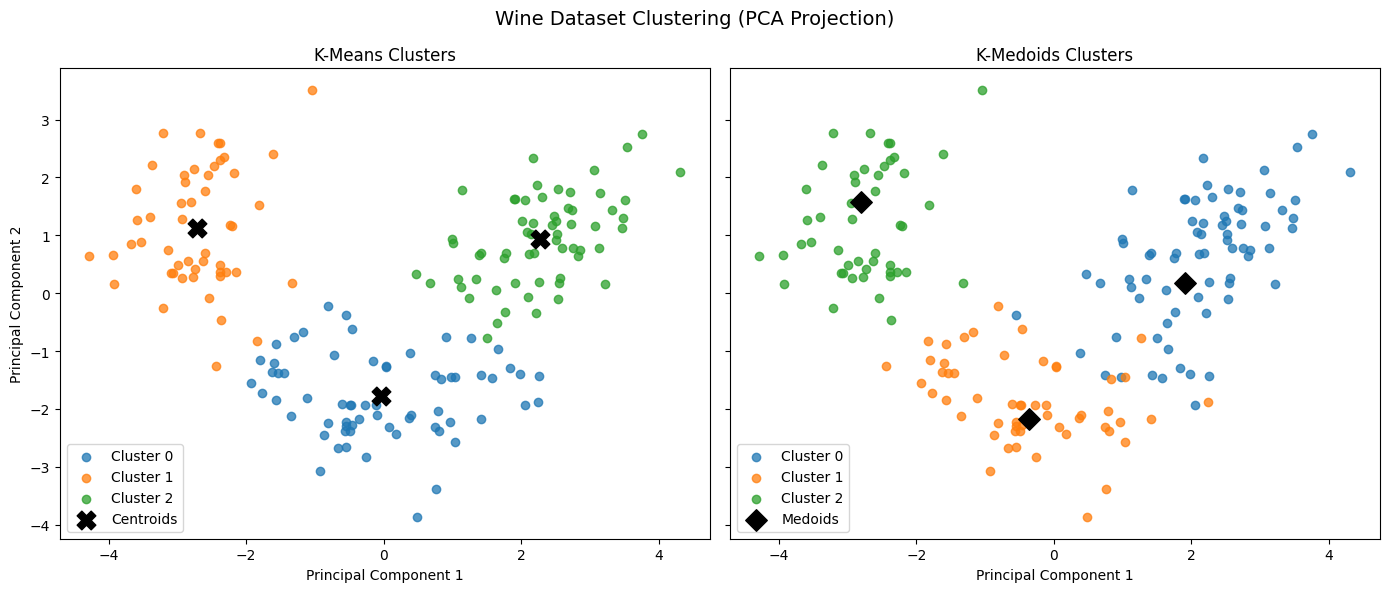

In [8]:
# Project observations and cluster representatives into one 2D space for comparison.
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)
kmeans_centers_pca = pca.transform(kmeans.cluster_centers_)
kmedoids_points_pca = X_pca[medoid_indices]

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)

# Plot both algorithms' assignments in the same PCA projection.
for cluster_id in range(N_CLUSTERS):
    points = kmeans_labels == cluster_id
    axes[0].scatter(
        X_pca[points, 0], X_pca[points, 1],
        label=f'Cluster {cluster_id}', alpha=0.75
    )

# Overlay K-Means centroids in PCA coordinates.
axes[0].scatter(
    kmeans_centers_pca[:, 0], kmeans_centers_pca[:, 1],
    marker='X', s=180, c='black', label='Centroids'
)
axes[0].set_title('K-Means Clusters')
axes[0].set_xlabel('Principal Component 1')
axes[0].set_ylabel('Principal Component 2')
axes[0].legend()

for cluster_id in range(N_CLUSTERS):
    points = kmedoids_labels == cluster_id
    axes[1].scatter(
        X_pca[points, 0], X_pca[points, 1],
        label=f'Cluster {cluster_id}', alpha=0.75
    )

# Overlay the selected observations that serve as K-Medoids medoids.
axes[1].scatter(
    kmedoids_points_pca[:, 0], kmedoids_points_pca[:, 1],
    marker='D', s=120, c='black', label='Medoids'
)
axes[1].set_title('K-Medoids Clusters')
axes[1].set_xlabel('Principal Component 1')
axes[1].legend()

fig.suptitle('Wine Dataset Clustering (PCA Projection)', fontsize=14)
plt.tight_layout()
plt.show()

In [9]:
# Compare both clustering algorithms across the two evaluation metrics.
results = pd.DataFrame({
    'Algorithm': ['K-Means', 'K-Medoids'],
    'Silhouette Score': [kmeans_silhouette, kmedoids_silhouette],
    'Adjusted Rand Index': [kmeans_ari, kmedoids_ari]
}).set_index('Algorithm')

display(results.round(4))

# Higher scores indicate better-separated clusters and closer agreement with known classes.
best_silhouette = results['Silhouette Score'].idxmax()
best_ari = results['Adjusted Rand Index'].idxmax()
print(f'Better-defined clusters by Silhouette Score: {best_silhouette}')
print(f'Closest agreement with known classes by ARI: {best_ari}')

,Silhouette Score,Adjusted Rand Index
Algorithm,,
K-Means,0.2849,0.8975
K-Medoids,0.2676,0.7411


Better-defined clusters by Silhouette Score: K-Means
Closest agreement with known classes by ARI: K-Means
